In [1]:
import pandas as pd
from statsbombpy import sb

# 1. Cargamos los eventos de la Final del Mundial (match_id: 3869685)
match_id = 3869685
df_eventos = sb.events(match_id=match_id)

# 2. Filtrar solo los eventos de tipo "Shot" (Tiros)
tiros = df_eventos[df_eventos['type'] == 'Shot'].copy()

# 3. Seleccionar las columnas clave que nos interesan
# Extraemos: Jugador, Equipo, Minuto, Resultado del tiro y el valor de xG
columnas_interes = ['player', 'team', 'minute', 'shot_outcome', 'shot_statsbomb_xg']
tiros_resumen = tiros[columnas_interes].sort_values(by='shot_statsbomb_xg', ascending=False)

# Mostrar los 5 tiros con mayor probabilidad de gol (xG más alto)
tiros_resumen.head()

c:\Users\fabio\AppData\Local\Programs\Python\Python315\Lib\site-packages\statsbombpy\api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


,player,team,minute,shot_outcome,shot_statsbomb_xg
4210,Lionel Andrés Messi Cuccittini,Argentina,22,Goal,0.7835
4241,Aurélien Djani Tchouaméni,France,123,Off T,0.7835
4240,Paulo Bruno Exequiel Dybala,Argentina,122,Goal,0.7835
4239,Kingsley Coman,France,121,Saved,0.7835
4238,Lionel Andrés Messi Cuccittini,Argentina,121,Goal,0.7835


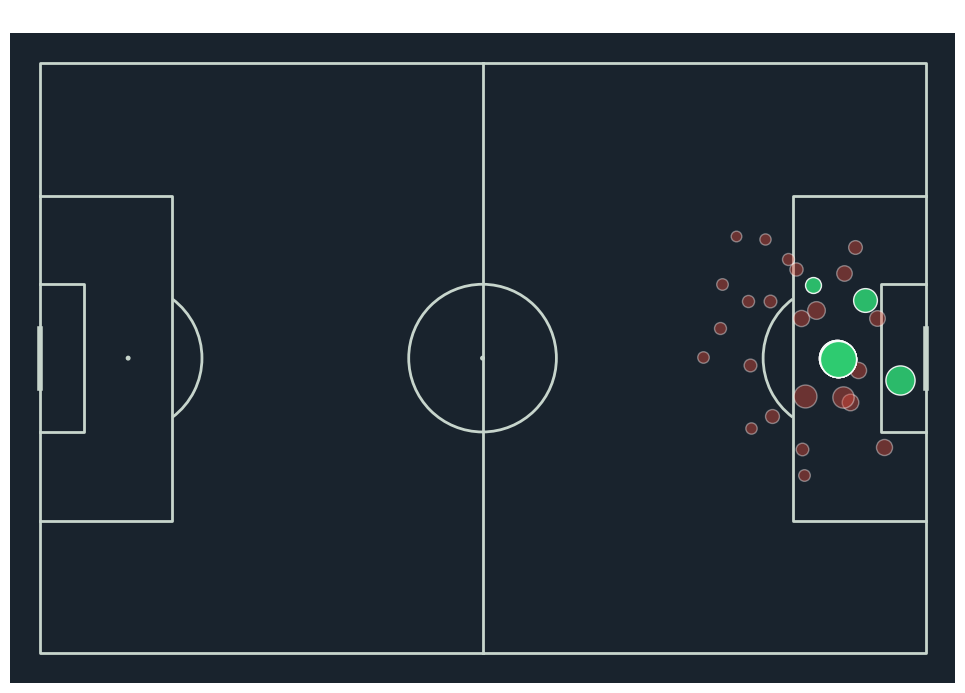

In [2]:
import matplotlib.pyplot as plt
from mplsoccer import Pitch

# 1. Creamos la cancha de StatsBomb orientada horizontalmente
cancha = Pitch(pitch_type='statsbomb', pitch_color='#19232d', line_color='#c7d5cc')
fig, ax = cancha.draw(figsize=(10, 7))

# 2. Recorremos cada tiro para dibujarlo individualmente
for _, tiro in tiros.iterrows():
    # Extraemos coordenadas X e Y de origen del tiro
    x_tiro = tiro['location'][0]
    y_tiro = tiro['location'][1]
    
    # Asignamos color según el resultado (Gol = Verde, Otro = Rojo/Opaco)
    es_gol = tiro['shot_outcome'] == 'Goal'
    color = '#2ecc71' if es_gol else '#e74c3c'
    alpha = 0.9 if es_gol else 0.4
    
    # Escalamos el tamaño del punto según su valor de xG
    xg_val = tiro['shot_statsbomb_xg']
    tamano = xg_val * 800 + 50 # Multiplicamos para que sea visualmente claro
    
    # Dibujamos el punto del remate
    cancha.scatter(x_tiro, y_tiro, s=tamano, color=color, alpha=alpha, edgecolors='white', ax=ax)

plt.title("🥅 Mapa de Tiros (Shot Map) - Argentina vs Francia", color='white', fontsize=14)
plt.show()

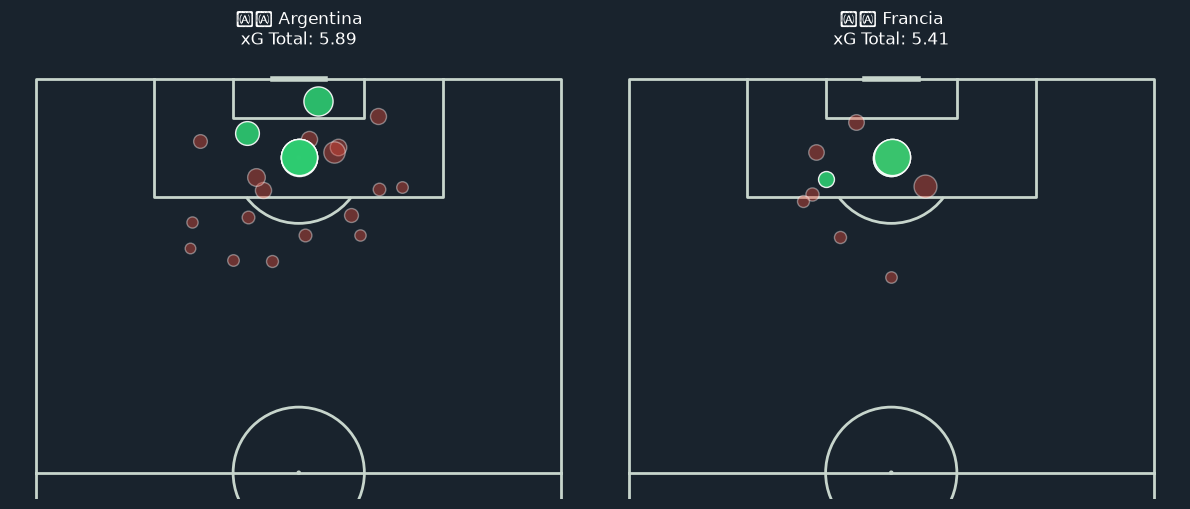

In [3]:
import matplotlib.pyplot as plt
from mplsoccer import VerticalPitch

# 1. Usamos VerticalPitch (cancha vertical) y half=True para mostrar solo la mitad de ataque
cancha_media = VerticalPitch(pitch_type='statsbomb', half=True, pitch_color='#19232d', line_color='#c7d5cc')
fig, (ax_arg, ax_fra) = plt.subplots(1, 2, figsize=(12, 6), facecolor='#19232d')

# Función para dibujar los tiros de un equipo en un eje (ax)
def dibujar_tiros_equipo(df_tiros, equipo, ax_target, titulo):
    cancha_media.draw(ax=ax_target)
    tiros_eq = df_tiros[df_tiros['team'] == equipo]
    
    for _, tiro in tiros_eq.iterrows():
        x_tiro, y_tiro = tiro['location'][0], tiro['location'][1]
        es_gol = tiro['shot_outcome'] == 'Goal'
        color = '#2ecc71' if es_gol else '#e74c3c'
        alpha = 0.9 if es_gol else 0.4
        tamano = tiro['shot_statsbomb_xg'] * 800 + 50
        
        cancha_media.scatter(x_tiro, y_tiro, s=tamano, color=color, alpha=alpha, edgecolors='white', ax=ax_target)
    
    # Calcular xG Total del equipo
    xg_total = tiros_eq['shot_statsbomb_xg'].sum()
    ax_target.set_title(f"{titulo}\nxG Total: {xg_total:.2f}", color='white', fontsize=12)

# Dibujamos ambos equipos lado a lado
dibujar_tiros_equipo(tiros, 'Argentina', ax_arg, "🇦🇷 Argentina")
dibujar_tiros_equipo(tiros, 'France', ax_fra, "🇫🇷 Francia")

plt.tight_layout()
plt.show()

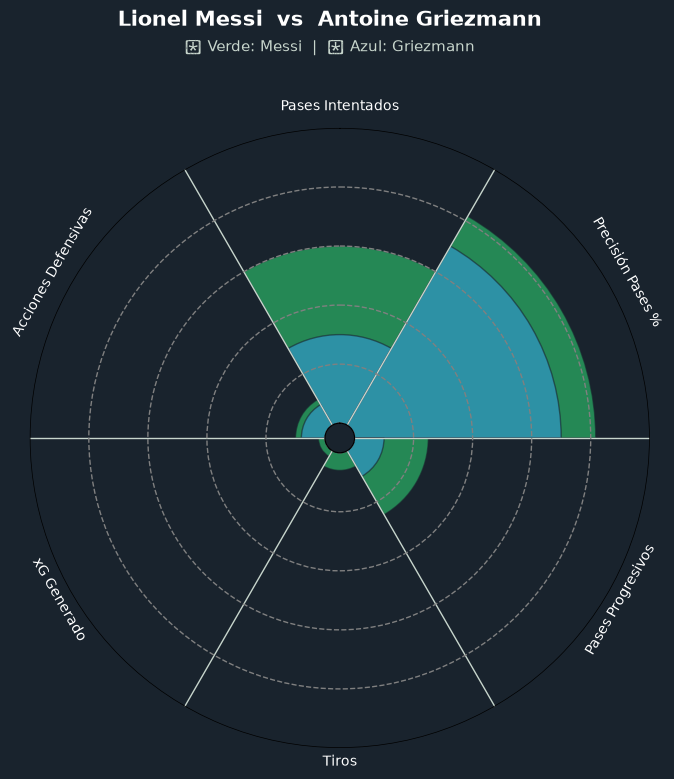

,Métrica,Lionel Messi,Antoine Griezmann
0,Pases Intentados,60.00,30.0
1,Precisión Pases %,81.70,70.0
2,Pases Progresivos,25.00,10.0
3,Tiros,6.00,0.0
4,xG Generado,2.24,0.0
5,Acciones Defensivas,10.00,8.0


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import PyPizza
from statsbombpy import sb

# 1. Cargamos el partido
df_eventos = sb.events(match_id=3869685)

# 2. Función auxiliar para calcular métricas de un jugador en este partido
def obtener_metrics_jugador(nombre):
    df_j = df_eventos[df_eventos['player'] == nombre]
    
    # Pases
    pases = df_j[df_j['type'] == 'Pass']
    total_pases = len(pases)
    p_comp = len(pases[pases['pass_outcome'].isna()])
    prec_pases = (p_comp / total_pases * 100) if total_pases > 0 else 0
    
    pases_prog = 0
    for _, p in pases.iterrows():
        if (p['pass_end_location'][0] - p['location'][0]) >= 10:
            pases_prog += 1
            
    # Tiros / xG
    tiros = df_j[df_j['type'] == 'Shot']
    total_tiros = len(tiros)
    xg_total = tiros['shot_statsbomb_xg'].sum() if total_tiros > 0 else 0
    
    # Recuperaciones / Entradas
    defensivas = len(df_j[df_j['type'].isin(['Duel', 'Interception', 'Ball Recovery'])])
    
    return [total_pases, round(prec_pases, 1), pases_prog, total_tiros, round(xg_total, 2), defensivas]

# 3. Parámetros y Valores
params = ["Pases Intentados", "Precisión Pases %", "Pases Progresivos", "Tiros", "xG Generado", "Acciones Defensivas"]
val_messi = obtener_metrics_jugador('Lionel Andrés Messi Cuccittini')
val_griezmann = obtener_metrics_jugador('Antoine Griezmann')

# 4. Configurar el gráfico de Radar
baker = PyPizza(
    params=params,
    background_color="#19232d",
    straight_line_color="#c7d5cc",
    straight_line_lw=1,
    last_circle_lw=1,
    other_circle_lw=1,
    inner_circle_size=5
)

fig, ax = baker.make_pizza(
    val_messi,
    compare_values=val_griezmann,
    figsize=(8, 8.5),
    param_location=106,
    kwargs_slices=dict(facecolor="#2ecc71", edgecolor="#19232d", linewidth=1, alpha=0.6),
    kwargs_compare=dict(facecolor="#3498db", edgecolor="#19232d", linewidth=1, alpha=0.6),
    kwargs_params=dict(color="white", fontsize=10),
    kwargs_values=dict(alpha=0),         # Oculta los números de Messi volviéndolos transparentes
    kwargs_compare_values=dict(alpha=0)  # Oculta los números de Griezmann volviéndolos transparentes
)

# Título y Leyenda arriba
fig.text(0.5, 0.98, "Lionel Messi  vs  Antoine Griezmann", size=15, ha="center", color="white", weight="bold")
fig.text(0.5, 0.95, "🟩 Verde: Messi  |  🟦 Azul: Griezmann", size=11, ha="center", color="#c7d5cc")

plt.show()

# 5. Tabla comparativa clara para acompañar el gráfico
df_comparativa = pd.DataFrame({
    'Métrica': params,
    'Lionel Messi': val_messi,
    'Antoine Griezmann': val_griezmann
})
df_comparativa

In [4]:
# Celda 1: Forzar la instalación/actualización dentro del entorno actual del cuaderno
%pip install --upgrade statsbombpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import Pitch

# 1. Usamos la URL raw directa de GitHub verified para un partido completo de StatsBomb
# (Partido ID: 3857255 - Japón vs España)
match_id = 3857255
url_eventos = f"https://raw.githubusercontent.com/statsbomb/open-data/master/data/events/{match_id}.json"

# Cargar eventos directamente en DataFrame
df_eventos = pd.read_json(url_eventos)

# 2. Extraer nombre de tipo de evento y equipo
df_eventos['type_name'] = df_eventos['type'].apply(lambda x: x['name'] if isinstance(x, dict) else '')
df_eventos['team_name'] = df_eventos['team'].apply(lambda x: x['name'] if isinstance(x, dict) else '')

# 3. Filtrar pases completados del equipo (Ejemplo: Japan)
def es_pase_completado(row):
    if row['type_name'] == 'Pass' and row['team_name'] == 'Japan':
        pass_dict = row.get('pass', {})
        if isinstance(pass_dict, dict):
            return 'outcome' not in pass_dict
    return False

pases_equipo = df_eventos[df_eventos.apply(es_pase_completado, axis=1)].copy()

# 4. Extraer jugador, receptor y coordenadas X, Y
pases_equipo['player_name'] = pases_equipo['player'].apply(lambda x: x['name'] if isinstance(x, dict) else '')
pases_equipo['recipient_name'] = pases_equipo['pass'].apply(
    lambda x: x.get('recipient', {}).get('name', '') if isinstance(x, dict) and isinstance(x.get('recipient'), dict) else ''
)
pases_equipo['x'] = pases_equipo['location'].apply(lambda loc: loc[0] if isinstance(loc, list) else None)
pases_equipo['y'] = pases_equipo['location'].apply(lambda loc: loc[1] if isinstance(loc, list) else None)

# Mostrar las primeras filas limpias
pases_equipo[['minute', 'player_name', 'recipient_name', 'x', 'y']].head()

,minute,player_name,recipient_name,x,y
95,1,Junya Ito,Takefusa Kubo,14.1,80.0
104,2,Hidemasa Morita,Daichi Kamada,35.0,53.4
107,2,Daichi Kamada,Ao Tanaka,39.9,51.1
126,2,Junya Ito,Ko Itakura,71.7,80.0
129,2,Ko Itakura,Maya Yoshida,46.1,67.3


In [9]:
# 1. Agrupar por jugador y calcular coordenadas promedio (x, y) y total de pases
posiciones_promedio = pases_equipo.groupby('player_name').agg(
    x_mean=('x', 'mean'),
    y_mean=('y', 'mean'),
    total_pases=('x', 'count')
).reset_index()

# 2. Ordenar de mayor a menor según el número de pases
posiciones_promedio = posiciones_promedio.sort_values(by='total_pases', ascending=False)

# 3. Mostrar la tabla de posiciones promedio
posiciones_promedio

,player_name,x_mean,y_mean,total_pases
3,Hidemasa Morita,46.680769,31.819231,26
9,Shogo Taniguchi,37.253846,14.407692,26
4,Junya Ito,57.665000,62.960000,20
0,Ao Tanaka,59.435000,52.345000,20
7,Maya Yoshida,31.629412,45.994118,17
6,Ko Itakura,30.162500,55.387500,16
10,Shūichi Gonda,14.490909,38.800000,11
1,Daichi Kamada,64.300000,28.360000,10
5,Kaoru Mitoma,64.475000,15.412500,8
14,Yuto Nagatomo,69.757143,5.700000,7


In [10]:
# 1. Agrupar por la pareja (pasador -> receptor) y contar cuántos pases hicieron entre sí
conexiones_pases = pases_equipo.groupby(['player_name', 'recipient_name']).size().reset_index(name='pass_count')

# 2. Unir con las posiciones promedio del PASADOR (Jugador A)
conexiones_pases = conexiones_pases.merge(
    posiciones_promedio[['player_name', 'x_mean', 'y_mean']], 
    on='player_name'
).rename(columns={'x_mean': 'x_start', 'y_mean': 'y_start'})

# 3. Unir con las posiciones promedio del RECEPTOR (Jugador B)
conexiones_pases = conexiones_pases.merge(
    posiciones_promedio[['player_name', 'x_mean', 'y_mean']], 
    left_on='recipient_name', 
    right_on='player_name', 
    suffixes=('', '_end')
).rename(columns={'x_mean': 'x_end', 'y_mean': 'y_end'})

# Limpiar columna duplicada de merge
conexiones_pases = conexiones_pases.drop(columns=['player_name_end'])

# 4. Filtrar conexiones débiles (por ejemplo, solo mostrar conexiones de 2 pases o más para no saturar el mapa)
conexiones_pases = conexiones_pases[conexiones_pases['pass_count'] >= 2].sort_values(by='pass_count', ascending=False)

conexiones_pases.head(10)

,player_name,recipient_name,pass_count,x_start,y_start,x_end,y_end
61,Shogo Taniguchi,Hidemasa Morita,9,37.253846,14.407692,46.680769,31.819231
17,Hidemasa Morita,Ao Tanaka,6,46.680769,31.819231,59.435000,52.345000
3,Ao Tanaka,Junya Ito,6,59.435000,52.345000,57.665000,62.960000
24,Hidemasa Morita,Shogo Taniguchi,6,46.680769,31.819231,37.253846,14.407692
27,Junya Ito,Ao Tanaka,5,57.665000,62.960000,59.435000,52.345000
34,Junya Ito,Takefusa Kubo,4,57.665000,62.960000,83.483333,29.816667
49,Maya Yoshida,Daichi Kamada,4,31.629412,45.994118,64.300000,28.360000
44,Ko Itakura,Junya Ito,4,30.162500,55.387500,57.665000,62.960000
54,Maya Yoshida,Shūichi Gonda,4,31.629412,45.994118,14.490909,38.800000
63,Shogo Taniguchi,Kaoru Mitoma,4,37.253846,14.407692,64.475000,15.412500


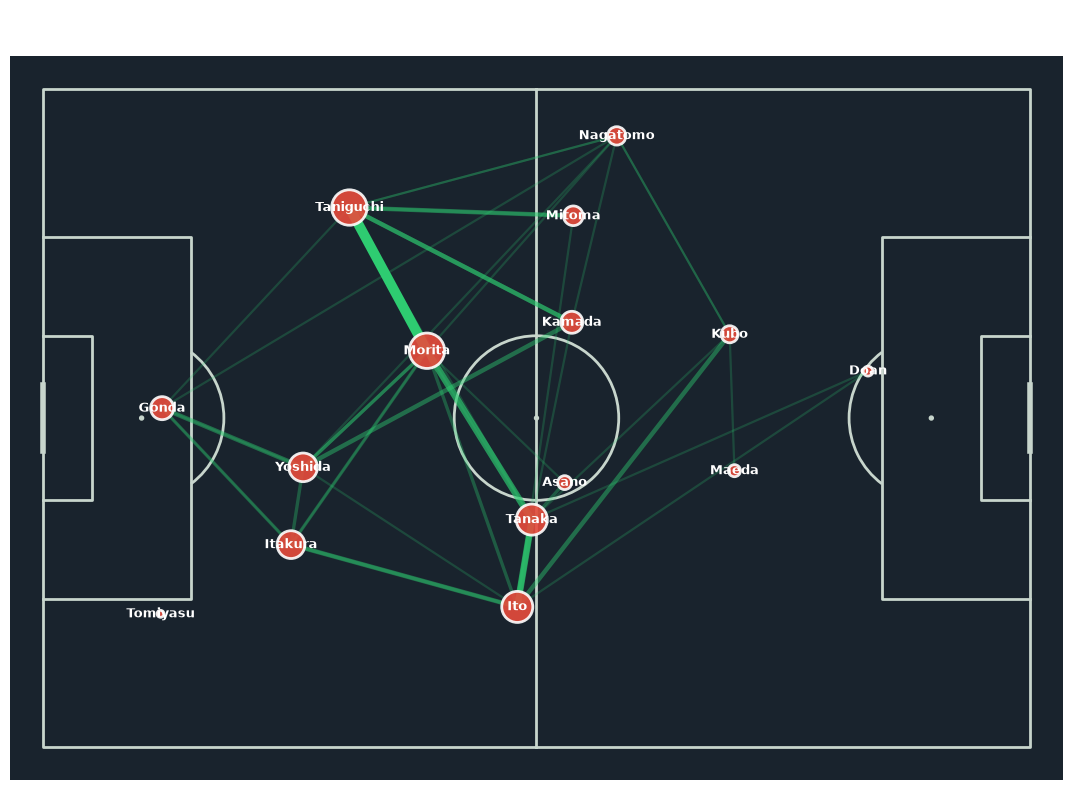

In [11]:
# 1. Crear el terreno de juego con mplsoccer
pitch = Pitch(pitch_type='statsbomb', pitch_color='#19232d', line_color='#c7d5cc')
fig, ax = pitch.draw(figsize=(12, 8))

# 2. Dibujar las LÍNEAS DE CONEXIÓN (Aristas)
for _, row in conexiones_pases.iterrows():
    # El grosor de la línea será proporcional a la cantidad de pases
    grosor_linea = row['pass_count'] * 0.8
    alpha_linea = min(row['pass_count'] / conexiones_pases['pass_count'].max(), 1.0)
    
    pitch.lines(
        row['x_start'], row['y_start'],
        row['x_end'], row['y_end'],
        ax=ax, color='#2ecc71', lw=grosor_linea, alpha=alpha_linea, zorder=1
    )

# 3. Dibujar los NODOS DE JUGADORES (Círculos)
nodes = pitch.scatter(
    posiciones_promedio['x_mean'], posiciones_promedio['y_mean'],
    s=posiciones_promedio['total_pases'] * 25, # El tamaño depende de los pases totales
    color='#e74c3c', edgecolors='white', linewidth=2, alpha=0.9, ax=ax, zorder=2
)

# 4. Escribir los NOMBRES de los jugadores sobre cada nodo
for _, row in posiciones_promedio.iterrows():
    # Extraer el apellido para que no ocupe tanto espacio
    apellido = row['player_name'].split()[-1]
    pitch.annotate(
        apellido,
        xy=(row['x_mean'], row['y_mean']),
        c='white', va='center', ha='center',
        size=9, weight='bold', ax=ax, zorder=3
    )

plt.title("Passing Network - Japan (Match ID: 3857255)\nTamaño del nodo: Volumen total | Linea: Frecuencia de pases entre parejas", color='white', fontsize=13)
plt.show()

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import Pitch

# 1. Cargamos el partido desde el JSON raw
match_id = 3857255  # Japón vs España
url = f"https://raw.githubusercontent.com/statsbomb/open-data/master/data/events/{match_id}.json"
df_eventos = pd.read_json(url)

# 2. Filtrar solo los tiros (Shot)
df_eventos['type_name'] = df_eventos['type'].apply(lambda x: x['name'] if isinstance(x, dict) else '')
df_tiros = df_eventos[df_eventos['type_name'] == 'Shot'].copy()

# 3. Extraer variables clave del tiro: equipo, jugador, coordenadas X, Y, xG y resultado
df_tiros['team_name'] = df_tiros['team'].apply(lambda x: x['name'] if isinstance(x, dict) else '')
df_tiros['player_name'] = df_tiros['player'].apply(lambda x: x['name'] if isinstance(x, dict) else '')
df_tiros['x'] = df_tiros['location'].apply(lambda loc: loc[0] if isinstance(loc, list) else None)
df_tiros['y'] = df_tiros['location'].apply(lambda loc: loc[1] if isinstance(loc, list) else None)

# Extraer xG y el resultado (Goal, Saved, Off Target, Blocked) del diccionario 'shot'
df_tiros['xg'] = df_tiros['shot'].apply(lambda x: x.get('statsbomb_xg', 0) if isinstance(x, dict) else 0)
df_tiros['outcome'] = df_tiros['shot'].apply(lambda x: x.get('outcome', {}).get('name', '') if isinstance(x, dict) else '')

# Mostrar la tabla limpia con los remates
df_tiros[['minute', 'team_name', 'player_name', 'xg', 'outcome', 'x', 'y']].head(10)

,minute,team_name,player_name,xg,outcome,x,y
369,6,Spain,Sergio Busquets i Burgos,0.032682,Off T,97.0,46.1
411,7,Japan,Junya Ito,0.042145,Off T,114.0,53.5
466,8,Spain,Álvaro Borja Morata Martín,0.063761,Saved,109.9,35.6
597,11,Spain,Álvaro Borja Morata Martín,0.331067,Goal,115.3,38.3
1208,22,Spain,Álvaro Borja Morata Martín,0.100938,Saved,104.7,51.6
1854,35,Japan,Daichi Kamada,0.033561,Blocked,107.0,54.5
2154,41,Spain,Daniel Olmo Carvajal,0.103853,Blocked,102.8,35.2
2475,47,Japan,Ritsu Doan,0.027778,Goal,100.5,55.8
2509,50,Japan,Ao Tanaka,0.872618,Goal,118.7,40.2
3139,69,Japan,Takuma Asano,0.131218,Off T,100.5,36.3


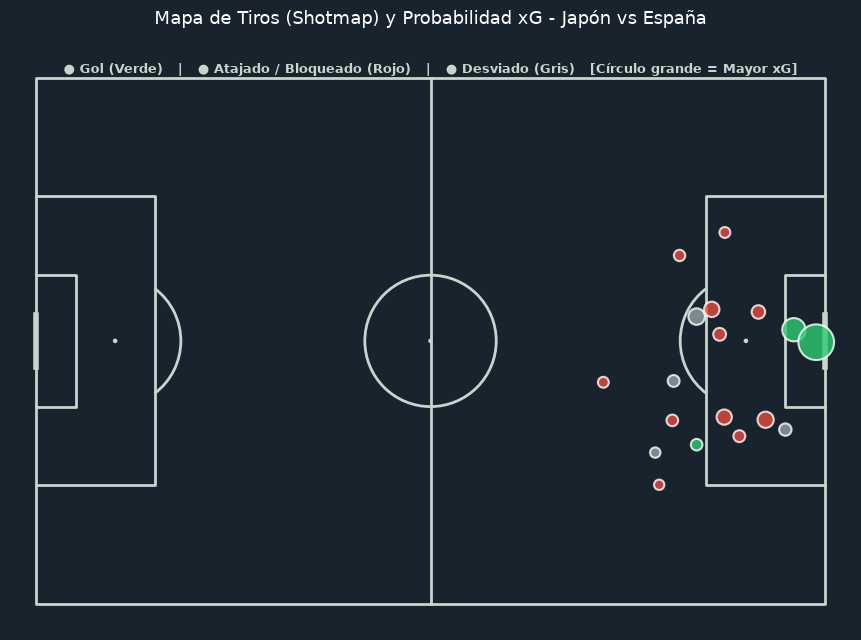

In [4]:
# 1. Crear el terreno de juego con fondo oscuro uniforme en la figura
pitch = Pitch(pitch_type='statsbomb', pitch_color='#19232d', line_color='#c7d5cc')
fig, ax = pitch.draw(figsize=(10, 6.5))
fig.set_facecolor('#19232d')

# 2. Asignar colores según el resultado del remate
def obtener_color_resultado(resultado):
    if resultado == 'Goal':
        return '#2ecc71'  # Verde para gol
    elif resultado in ['Saved', 'Blocked']:
        return '#e74c3c'  # Rojo para atajado/bloqueado
    else:
        return '#95a5a6'  # Gris para desviado

df_tiros['color'] = df_tiros['outcome'].apply(obtener_color_resultado)

# 3. Dibujar los remates en la cancha
pitch.scatter(
    df_tiros['x'], df_tiros['y'],
    s=df_tiros['xg'] * 700 + 50,
    color=df_tiros['color'],
    edgecolors='white',
    linewidth=1.5,
    alpha=0.8,
    ax=ax
)

# 4. Título y Leyenda con viñetas limpias (●)
ax.set_title("Mapa de Tiros (Shotmap) y Probabilidad xG - Japón vs España", color='white', fontsize=13, pad=20)
fig.text(0.5, 0.88, "● Gol (Verde)   |   ● Atajado / Bloqueado (Rojo)   |   ● Desviado (Gris)   [Círculo grande = Mayor xG]", 
         ha='center', color='#c7d5cc', fontsize=9.5, weight='bold')

plt.show()